In [9]:
from typing import Dict, TypedDict
from langgraph.graph import StateGraph, END
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI

from IPython.display import display, Image
from langchain_core.runnables.graph import MermaidDrawMethod
from dotenv import load_dotenv
import os

from groq import Groq

from langchain_groq import ChatGroq




In [18]:
from typing import TypedDict, Optional

class State(TypedDict):
    query: str
    categoria: Optional[str]
    sentimento: Optional[str]
    resposta: Optional[str]

    query: str
    categoria: str
    sentimento: str
    resposta: str
    

In [ ]:
from langchain_groq import ChatGroq
from langchain_core.prompts import ChatPromptTemplate

# Inicializa o modelo Groq
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    api_key="gsk_"
)

def categorize(state: State) -> State:
    """Categoriza a consulta do cliente em Técnica, Faturamento ou Geral."""
    prompt = ChatPromptTemplate.from_template(
        "Categorize a seguinte consulta do cliente em uma destas categorias: "
        "Técnica, Faturamento, Geral. "
        "Responda apenas com o nome da categoria. Consulta: {query}"
    )
    chain = prompt | llm
    categoria = chain.invoke({"query": state["query"]}).content.strip()
    return {"categoria": categoria}


def analyze_sentiment(state: State) -> State:
    """Analisa o sentimento da consulta do cliente como Positivo, Neutro ou Negativo."""
    prompt = ChatPromptTemplate.from_template(
        "Analise o sentimento da seguinte consulta do cliente. "
        "Responda apenas com 'Positivo', 'Neutro' ou 'Negativo'. "
        "Consulta: {query}"
    )
    chain = prompt | llm
    sentimento = chain.invoke({"query": state["query"]}).content.strip()
    return {"sentimento": sentimento}


def handle_technical(state: State) -> State:
    """Fornece uma resposta de suporte técnico para a consulta."""
    prompt = ChatPromptTemplate.from_template(
        "Forneça uma resposta de suporte técnico para a seguinte consulta: {query}"
    )
    chain = prompt | llm
    resposta = chain.invoke({"query": state["query"]}).content
    return {"resposta": resposta}


def handle_billing(state: State) -> State:
    """Fornece uma resposta de suporte de faturamento para a consulta."""
    prompt = ChatPromptTemplate.from_template(
        "Forneça uma resposta de suporte de faturamento para a seguinte consulta: {query}"
    )
    chain = prompt | llm
    resposta = chain.invoke({"query": state["query"]}).content
    return {"resposta": resposta}


def handle_general(state: State) -> State:
    """Fornece uma resposta de suporte geral para a consulta."""
    prompt = ChatPromptTemplate.from_template(
        "Forneça uma resposta de suporte geral para a seguinte consulta: {query}"
    )
    chain = prompt | llm
    resposta = chain.invoke({"query": state["query"]}).content
    return {"resposta": resposta}
    
def escalate(state: State) -> State:
    """Escala a consulta para um agente humano devido ao sentimento negativo."""
    return {"resposta": "Esta consulta foi escalada para um agente humano devido ao seu sentimento negativo."}

def route_query(state: State) -> str:
    """Roteia a consulta com base em seu sentimento e categoria."""
    if state["sentimento"] == "Negativo":
        return "escalate"
    elif state["categoria"] == "Técnica":
        return "handle_technical"
    elif state["categoria"] == "Faturamento":
        return "handle_billing"
    else:
        return "handle_general"


In [20]:
 #Criar o grafo
from langgraph.graph import StateGraph, START, END
workflow = StateGraph(State)

# Adicionar nós
workflow.add_node("categorize", categorize)
workflow.add_node("analyze_sentiment", analyze_sentiment)
workflow.add_node("handle_technical", handle_technical)
workflow.add_node("handle_billing", handle_billing)
workflow.add_node("handle_general", handle_general)
workflow.add_node("escalate", escalate)

# Adicionar arestas
workflow.add_edge("categorize", "analyze_sentiment")
workflow.add_conditional_edges(
    "analyze_sentiment",
    route_query,
    {
        "handle_technical": "handle_technical",
        "handle_billing": "handle_billing",
        "handle_general": "handle_general",
        "escalate": "escalate"
    }
)
workflow.add_edge("handle_technical", END)
workflow.add_edge("handle_billing", END)
workflow.add_edge("handle_general", END)
workflow.add_edge("escalate", END)

# Definir ponto de entrada
workflow.set_entry_point("categorize")

# Compilar o grafo
app = workflow.compile()

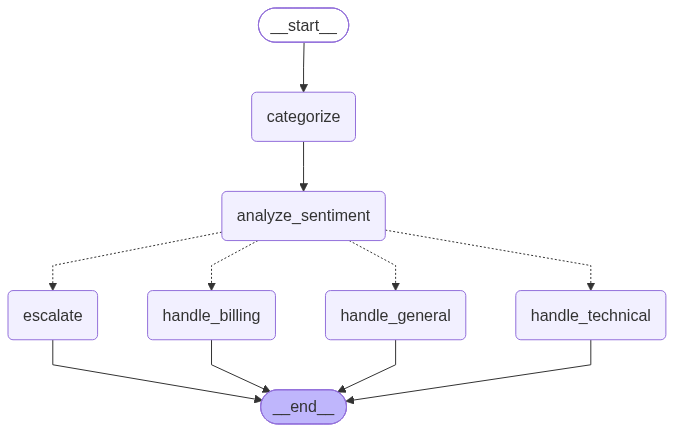

In [21]:
from IPython.display import Image, display
from langchain_core.runnables.graph import MermaidDrawMethod
display(
    Image(
        app.get_graph().draw_mermaid_png(
            draw_method=MermaidDrawMethod.API,
        )
    )
)

In [23]:
from typing import Dict, List, Any, Optional

def executar_suporte_ao_cliente(consulta: str) -> Dict[str, str]:
    """Processa uma consulta do cliente através do fluxo de trabalho LangGraph.

    Args:
        consulta (str): A consulta do cliente

    Returns:
        Dict[str, str]: Um dicionário contendo a categoria, o sentimento e a resposta da consulta
    """
    resultados = app.invoke({"query": consulta})
    return {
        "categoria": resultados["categoria"],
        "sentimento": resultados["sentimento"],
        "resposta": resultados["resposta"]
    }

# Testes

# escalar
consulta = "Minha conexão com a internet fica caindo. Você pode me ajudar?"
resultado = executar_suporte_ao_cliente(consulta)
print(f"Consulta: {consulta}")
print(f"Categoria: {resultado['categoria']}")
print(f"Sentimento: {resultado['sentimento']}")
print(f"Resposta: {resultado['resposta']}")
print("\n")

# lidar_com_tecnico
consulta = "Como fazer fazer um repositorio no docker"
resultado = executar_suporte_ao_cliente(consulta)
print(f"Consulta: {consulta}")
print(f"Categoria: {resultado['categoria']}")
print(f"Sentimento: {resultado['sentimento']}")
print(f"Resposta: {resultado['resposta']}")
print("\n")

# lidar_com_faturamento
consulta = "que praia linda, onde fica?"
resultado = executar_suporte_ao_cliente(consulta)
print(f"Consulta: {consulta}")
print(f"Categoria: {resultado['categoria']}")
print(f"Sentimento: {resultado['sentimento']}")
print(f"Resposta: {resultado['resposta']}")
print("\n")

# lidar_com_geral
consulta = "Quais são os horários de funcionamento?"
resultado = executar_suporte_ao_cliente(consulta)
print(f"Consulta: {consulta}")
print(f"Categoria: {resultado['categoria']}")
print(f"Sentimento: {resultado['sentimento']}")
print(f"Resposta: {resultado['resposta']}")

Consulta: Minha conexão com a internet fica caindo. Você pode me ajudar?
Categoria: Técnica
Sentimento: Negativo
Resposta: Esta consulta foi escalada para um agente humano devido ao seu sentimento negativo.


Consulta: Como fazer fazer um repositorio no docker
Categoria: Técnica
Sentimento: Neutro
Resposta: **Suporte Técnico – Como criar um repositório (registry) no Docker**

Olá! Vamos ajudá‑lo a criar um repositório Docker onde você possa armazenar e compartilhar suas imagens. Existem duas abordagens principais:

1. **Usar um repositório público/privado já existente (Docker Hub, GitHub Container Registry, GitLab Container Registry, etc.)**  
2. **Hospedar seu próprio registry privado (Docker Registry) em um servidor ou máquina local.**

A seguir, detalhamos ambas as opções, com comandos, exemplos e dicas de troubleshooting.

---

## 1️⃣ Usando um repositório já pronto (Docker Hub como exemplo)

### Passo a passo

| Etapa | O que fazer | Comando / Ação |
|------|-------------|--------